# Task 7 — Time Series Breakdown of Retail Sales

**Elevvo Data Analytics Internship — Task 7 (Level 3)**

**Dataset:** Walmart Sales Forecasting (Kaggle) — `train.csv` (421,570 weekly store-department records, Feb 2010 – Oct 2012), `stores.csv` (store type and size), `features.csv` (temperature, fuel price, CPI, unemployment, markdowns).

**What this notebook does**

1. Combine weekly sales with store and economic attributes.
2. Build the monthly revenue series and read the trend with a 12-month moving average.
3. Quantify seasonality (month-of-year index, year × month heatmap) and the holiday effect.
4. Break revenue down by *product* (department) and by store format, which is the closest thing this dataset offers to a region.
5. Bonus: forecast with exponential smoothing and benchmark it against a rolling-mean baseline.

**Note on "region":** the Walmart dataset contains no state or city field — only `Store`, `Type` (A/B/C) and `Size`. Store format is therefore used as the regional proxy and is labelled as such throughout.


## 1. Load and combine the three files

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.titlesize'] = 11

DATA = Path('../datasets')
OUT = Path('.')

train = pd.read_csv(DATA / 'walmart_train.csv', parse_dates=['Date'])
stores = pd.read_csv(DATA / 'walmart_stores.csv', lineterminator='\r')
feat = pd.read_csv(DATA / 'walmart_features.csv', parse_dates=['Date'])

print('train   ', train.shape)
print('stores  ', stores.shape)
print('features', feat.shape)
print('date range:', train.Date.min().date(), '->', train.Date.max().date())
print('stores:', train.Store.nunique(), '| departments:', train.Dept.nunique())


train    (421570, 5)
stores   (45, 3)
features (8190, 12)
date range: 2010-02-05 -> 2012-10-26
stores: 45 | departments: 81


In [2]:
df = (train
      .merge(stores, on='Store', how='left')
      .merge(feat[['Store', 'Date', 'Temperature', 'Fuel_Price', 'CPI', 'Unemployment']],
             on=['Store', 'Date'], how='left'))

df['Year'] = df.Date.dt.year
df['Month'] = df.Date.dt.month
df['SizeBand'] = pd.cut(df.Size, [0, 50_000, 100_000, 150_000, 250_000],
                        labels=['<50k sqft', '50-100k', '100-150k', '150k+'])

print('joined:', df.shape, '| negative or zero sales rows:', (df.Weekly_Sales <= 0).sum())
print('missing CPI:', df.CPI.isna().sum(), '| missing store type:', df.Type.isna().sum())
df.head()


joined: (421570, 14) | negative or zero sales rows: 1358
missing CPI: 0 | missing store type: 0


,Store,Dept,Date,Weekly_Sales,IsHoliday,Type,Size,Temperature,Fuel_Price,CPI,Unemployment,Year,Month,SizeBand
0,1,1,2010-02-05,24924.50,False,A,151315,42.31,2.572,211.096358,8.106,2010,2,150k+
1,1,1,2010-02-12,46039.49,True,A,151315,38.51,2.548,211.242170,8.106,2010,2,150k+
2,1,1,2010-02-19,41595.55,False,A,151315,39.93,2.514,211.289143,8.106,2010,2,150k+
3,1,1,2010-02-26,19403.54,False,A,151315,46.63,2.561,211.319643,8.106,2010,2,150k+
4,1,1,2010-03-05,21827.90,False,A,151315,46.50,2.625,211.350143,8.106,2010,3,150k+


## 2. Monthly revenue trend

Weekly figures are summed into calendar months (each week is assigned to the month of its Friday end-date). The 12-month moving average removes the seasonal saw-tooth and exposes the underlying direction.


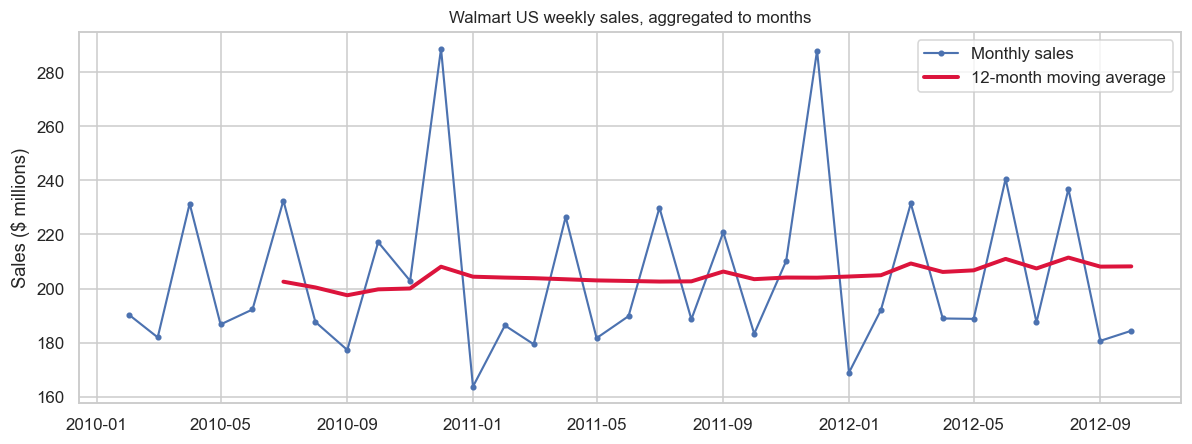

total sales      $6.74B
average month    $204.2M
best month       Dec 2010 at $288.8M
weakest month    Jan 2011 at $163.7M
last 12m vs prior 12m: +2.3%


In [3]:
monthly = (df.groupby(pd.Grouper(key='Date', freq='MS'))['Weekly_Sales']
             .sum().to_frame('Sales'))
monthly['Rolling12'] = monthly.Sales.rolling(12, min_periods=6).mean()
monthly['MoM_%'] = monthly.Sales.pct_change() * 100
monthly['YoY_%'] = monthly.Sales.pct_change(12) * 100

fig, ax = plt.subplots(figsize=(11, 4.2))
ax.plot(monthly.index, monthly.Sales / 1e6, marker='o', ms=3, lw=1.4, label='Monthly sales')
ax.plot(monthly.index, monthly.Rolling12 / 1e6, lw=2.6, color='crimson', label='12-month moving average')
ax.set_title('Walmart US weekly sales, aggregated to months')
ax.set_ylabel('Sales ($ millions)')
ax.legend()
plt.tight_layout()
plt.savefig(OUT / 'fig_trend.png', bbox_inches='tight')
plt.show()

print(f"total sales      ${df.Weekly_Sales.sum()/1e9:.2f}B")
print(f"average month    ${monthly.Sales.mean()/1e6:.1f}M")
print(f"best month       {monthly.Sales.idxmax():%b %Y} at ${monthly.Sales.max()/1e6:.1f}M")
print(f"weakest month    {monthly.Sales.idxmin():%b %Y} at ${monthly.Sales.min()/1e6:.1f}M")
print(f"last 12m vs prior 12m: {monthly.Sales[-12:].sum()/monthly.Sales[-24:-12].sum()-1:+.1%}")


## 3. Year-over-year view

Overlaying whole years on a shared month axis makes the year-on-year direction and the shape of the seasonal curve comparable at a glance.


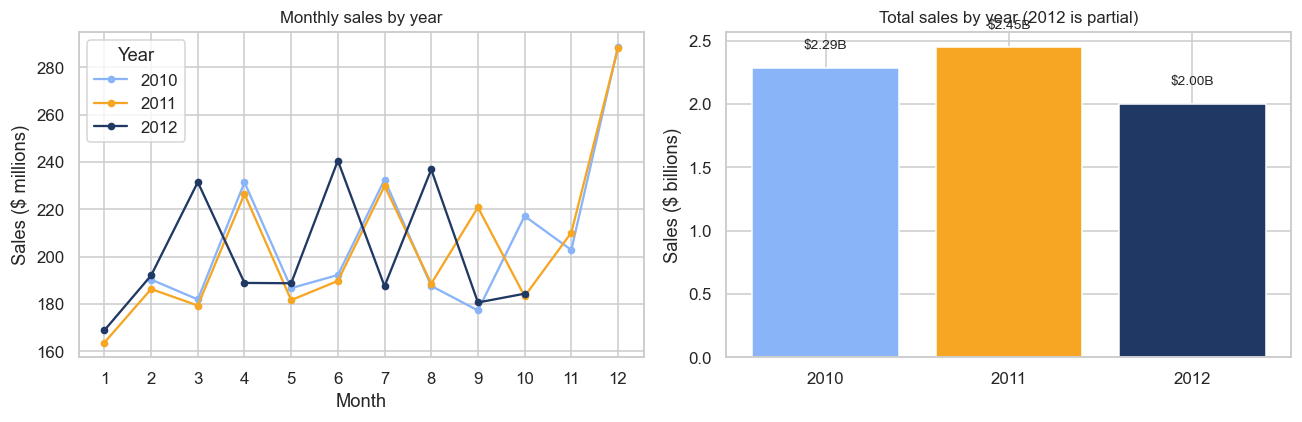

2012 covers Feb–Oct only, so its total is not comparable to full years.
2012-10-26


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

years = [2010, 2011, 2012]
palette = {2010: '#8ab4f8', 2011: '#f6a623', 2012: '#1f3864'}
for y in years:
    s = monthly[monthly.index.year == y]
    axes[0].plot(s.index.month, s.Sales / 1e6, marker='o', ms=4, label=str(y), color=palette[y])
axes[0].set_xticks(range(1, 13))
axes[0].set_xlabel('Month')
axes[0].set_ylabel('Sales ($ millions)')
axes[0].set_title('Monthly sales by year')
axes[0].legend(title='Year')

yearly = df.groupby('Year').Weekly_Sales.sum() / 1e9
axes[1].bar(yearly.index.astype(str), yearly.values, color=['#8ab4f8', '#f6a623', '#1f3864'])
axes[1].set_title('Total sales by year (2012 is partial)')
axes[1].set_ylabel('Sales ($ billions)')
for i, v in enumerate(yearly.values):
    axes[1].text(i, v + 0.15, f'${v:.2f}B', ha='center', fontsize=9)

plt.tight_layout()
plt.savefig(OUT / 'fig_yoy.png', bbox_inches='tight')
plt.show()

print('2012 covers Feb–Oct only, so its total is not comparable to full years.')
print(df[df.Year == 2012].Date.max().date())


## 4. Seasonality

The seasonality index is each calendar month's average sales divided by the average month, so 1.00 is a "normal" month and 1.20 means 20% above average.


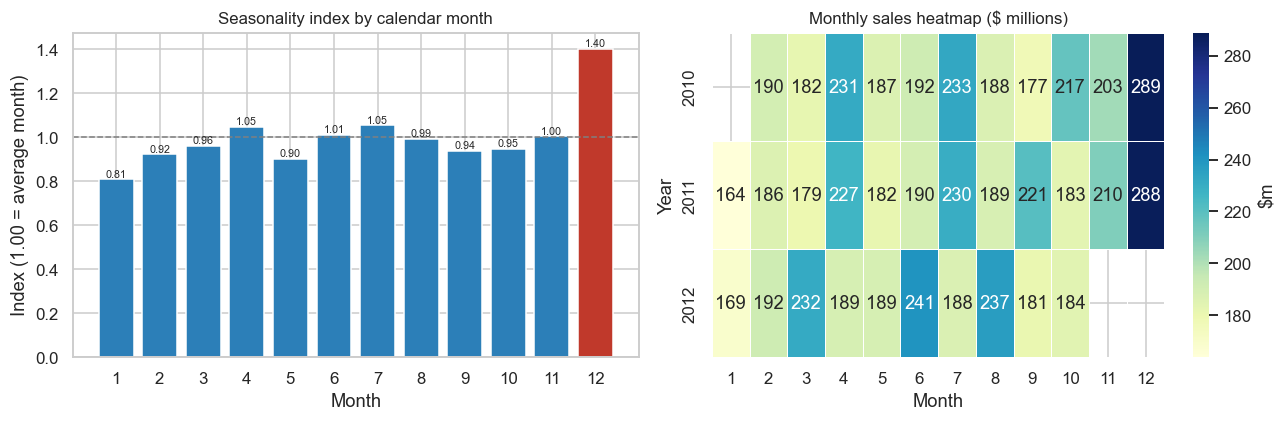

strongest months: 12, 7, 4
Month
12    1.403
7     1.054
4     1.049


In [5]:
seasonal = (monthly.assign(Month=monthly.index.month)
                     .groupby('Month').Sales.mean())
index = seasonal / seasonal.mean()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

cols = ['#c0392b' if v == index.max() else '#2c7fb8' for v in index.values]
axes[0].bar(index.index, index.values, color=cols)
axes[0].axhline(1, color='grey', ls='--', lw=1)
axes[0].set_xticks(range(1, 13))
axes[0].set_title('Seasonality index by calendar month')
axes[0].set_xlabel('Month')
axes[0].set_ylabel('Index (1.00 = average month)')
for m, v in index.items():
    axes[0].text(m, v + 0.01, f'{v:.2f}', ha='center', fontsize=7)

heat = monthly.assign(Year=monthly.index.year, Month=monthly.index.month).pivot_table(
    index='Year', columns='Month', values='Sales') / 1e6
sns.heatmap(heat, annot=True, fmt='.0f', cmap='YlGnBu', cbar_kws={'label': '$m'},
            ax=axes[1], linewidths=.5)
axes[1].set_title('Monthly sales heatmap ($ millions)')
axes[1].set_xlabel('Month')
axes[1].set_ylabel('Year')

plt.tight_layout()
plt.savefig(OUT / 'fig_seasonality.png', bbox_inches='tight')
plt.show()

print('strongest months:', ', '.join(f'{m}' for m in index.nlargest(3).index))
print(index.sort_values(ascending=False).head(3).round(3).to_string())


## 5. Holiday effect

`IsHoliday` flags four weeks: Super Bowl, Labour Day, Thanksgiving and Christmas. Comparing holiday weeks with ordinary weeks isolates the promotional spike.


average holiday week: $50.5M
average ordinary week: $46.9M
holiday lift: +7.8%


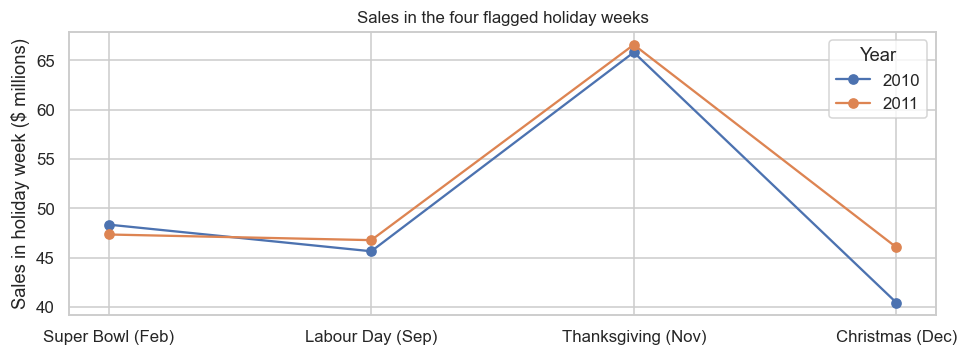

      Date  Weekly_Sales
2011-02-11   47336192.79
2011-09-09   46763227.53
2011-11-25   66593605.26
2011-12-30   46042461.04


In [6]:
weekly = df.groupby(['Date', 'IsHoliday']).Weekly_Sales.sum().reset_index()
hol = weekly.groupby('IsHoliday').Weekly_Sales.mean()
lift = hol[True] / hol[False] - 1
print(f"average holiday week: ${hol[True]/1e6:.1f}M")
print(f"average ordinary week: ${hol[False]/1e6:.1f}M")
print(f"holiday lift: {lift:+.1%}")

# the four flagged weeks per year, in date order
flagged = weekly[weekly.IsHoliday].sort_values('Date')
flagged['Year'] = flagged.Date.dt.year
fig, ax = plt.subplots(figsize=(9, 3.4))
for y in [2010, 2011]:
    s = flagged[flagged.Year == y]
    ax.plot(range(len(s)), s.Weekly_Sales / 1e6, marker='o', label=str(y))
ax.set_xticks(range(4))
ax.set_xticklabels(['Super Bowl (Feb)', 'Labour Day (Sep)', 'Thanksgiving (Nov)', 'Christmas (Dec)'])
ax.set_ylabel('Sales in holiday week ($ millions)')
ax.set_title('Sales in the four flagged holiday weeks')
ax.legend(title='Year')
plt.tight_layout()
plt.savefig(OUT / 'fig_holidays.png', bbox_inches='tight')
plt.show()

print(flagged[flagged.Year == 2011][['Date', 'Weekly_Sales']].to_string(index=False))


## 6. Breakdown by product — department over time

`Dept` is the product dimension. The ten largest departments are tracked month by month, and each one's change from 2010 to comparable months in 2012 shows which parts of the assortment are growing.


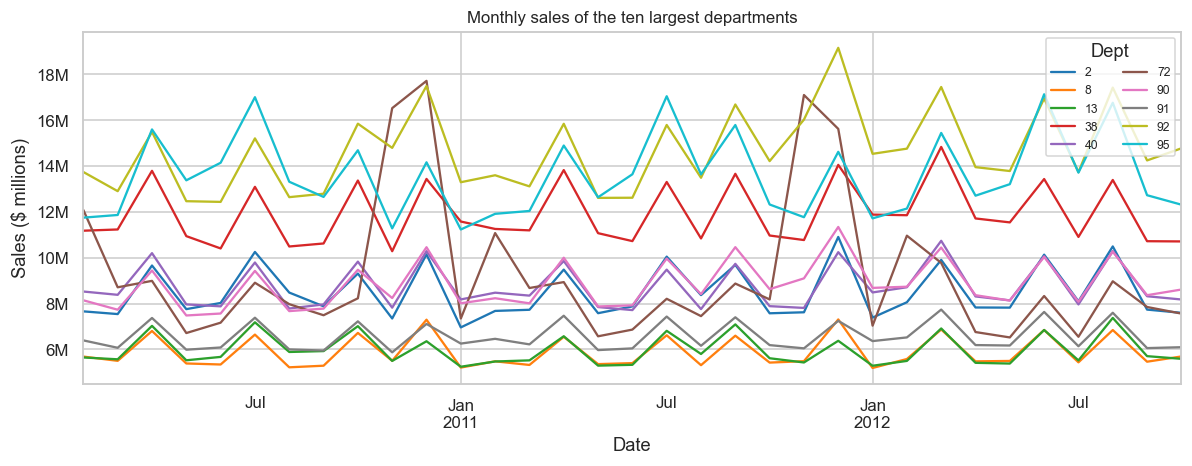

top departments by revenue:
Dept
92    7.2
95    6.7
38    5.8
72    4.5
90    4.3
40    4.3
2     4.2
91    3.2
13    2.9
8     2.9
top 10 departments = 46.0% of all sales


In [7]:
top_depts = df.groupby('Dept').Weekly_Sales.sum().nlargest(10).index
dept_month = (df[df.Dept.isin(top_depts)]
              .groupby([pd.Grouper(key='Date', freq='MS'), 'Dept']).Weekly_Sales.sum()
              .unstack())

fig, ax = plt.subplots(figsize=(11, 4.4))
dept_month.plot(ax=ax, lw=1.5, colormap='tab10')
ax.set_title('Monthly sales of the ten largest departments')
ax.set_ylabel('Sales ($ millions)')
ax.yaxis.set_major_formatter(lambda v, _: f'{v/1e6:.0f}M')
ax.legend(title='Dept', ncol=2, fontsize=8)
plt.tight_layout()
plt.savefig(OUT / 'fig_dept_trend.png', bbox_inches='tight')
plt.show()

share = df.groupby('Dept').Weekly_Sales.sum().nlargest(10)
print('top departments by revenue:')
print((share / df.Weekly_Sales.sum() * 100).round(1).to_string())
print(f"top 10 departments = {share.sum()/df.Weekly_Sales.sum():.1%} of all sales")


In [8]:
# like-for-like: 2012 only reaches October, so compare Feb-Oct 2010 with Feb-Oct 2012
def dept_feb_oct(dept, year):
    s = df[(df.Dept == dept) & (df.Year == year) & (df.Month.between(2, 10))]
    return s.Weekly_Sales.sum()

rows = []
for d in top_depts:
    a, b = dept_feb_oct(d, 2010), dept_feb_oct(d, 2012)
    rows.append({'Dept': d, 'Feb-Oct 2010': a, 'Feb-Oct 2012': b, 'change_%': (b / a - 1) * 100})
growth = pd.DataFrame(rows).sort_values('change_%', ascending=False)

print('Department growth, like-for-like (Feb-Oct 2010 vs Feb-Oct 2012):')
print(growth.assign(**{'Feb-Oct 2010': growth['Feb-Oct 2010'] / 1e6,
                       'Feb-Oct 2012': growth['Feb-Oct 2012'] / 1e6})
        .rename(columns={'Feb-Oct 2010': '2010_$m', 'Feb-Oct 2012': '2012_$m'})
        .round(1).to_string(index=False))
print(f"growing: {(growth['change_%'] > 0).sum()} of {len(growth)} top departments")


Department growth, like-for-like (Feb-Oct 2010 vs Feb-Oct 2012):
 Dept  2010_$m  2012_$m  change_%
   92    123.5    137.1      11.0
   90     74.7     81.0       8.5
   38    105.1    109.1       3.8
   40     78.3     80.7       3.1
   91     58.4     60.1       2.9
    8     52.6     53.7       2.1
    2     76.6     77.7       1.4
   95    124.4    126.2       1.4
   13     55.4     54.2      -2.2
   72     76.3     73.3      -3.9
growing: 8 of 10 top departments


## 7. Breakdown by store format (regional proxy)

The dataset has no geography, so store format and size band are the available regional cuts: type A stores are the largest, C the smallest.


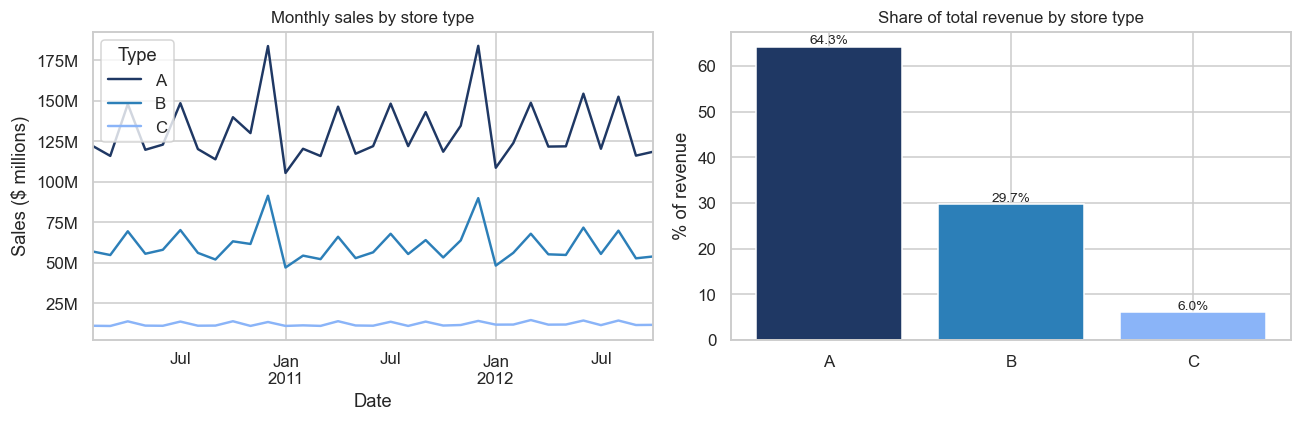

      stores  revenue_share_%  avg_weekly_sales_$
Type                                             
A         22             64.3             20100.0
B         17             29.7             12237.0
C          6              6.0              9520.0


In [9]:
type_month = (df.groupby([pd.Grouper(key='Date', freq='MS'), 'Type']).Weekly_Sales.sum()
                .unstack())
type_share = df.groupby('Type').Weekly_Sales.sum()
type_share = type_share / type_share.sum()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
type_month.plot(ax=axes[0], lw=1.6, color=['#1f3864', '#2c7fb8', '#8ab4f8'])
axes[0].set_title('Monthly sales by store type')
axes[0].set_ylabel('Sales ($ millions)')
axes[0].yaxis.set_major_formatter(lambda v, _: f'{v/1e6:.0f}M')

axes[1].bar(type_share.index, type_share.values * 100, color=['#1f3864', '#2c7fb8', '#8ab4f8'])
axes[1].set_title('Share of total revenue by store type')
axes[1].set_ylabel('% of revenue')
for i, v in enumerate(type_share.values * 100):
    axes[1].text(i, v + 0.6, f'{v:.1f}%', ha='center', fontsize=9)

plt.tight_layout()
plt.savefig(OUT / 'fig_type.png', bbox_inches='tight')
plt.show()

print(pd.DataFrame({'stores': df.groupby('Type').Store.nunique(),
                    'revenue_share_%': (type_share * 100).round(1),
                    'avg_weekly_sales_$': df.groupby('Type').Weekly_Sales.mean().round(0)}).to_string())


## 8. Bonus — forecasting with exponential smoothing

Holt-Winters (additive trend and seasonality, 12-month period) is fitted on the first 24 months and asked to predict the remaining 9 — statsmodels needs two full seasonal cycles to initialise the seasonal component. It is benchmarked against two naive baselines: last value repeated, and a 3-month rolling mean.


Holt-Winters MAPE : 14.4%
last-value MAPE   : 16.0%
3-month mean MAPE : 14.6%


C:\Users\guyaw\anaconda3\Lib\site-packages\statsmodels\tsa\holtwinters\model.py:903: ConvergenceWarning: Optimization failed to converge. Check mle_retvals.
  warnings.warn(


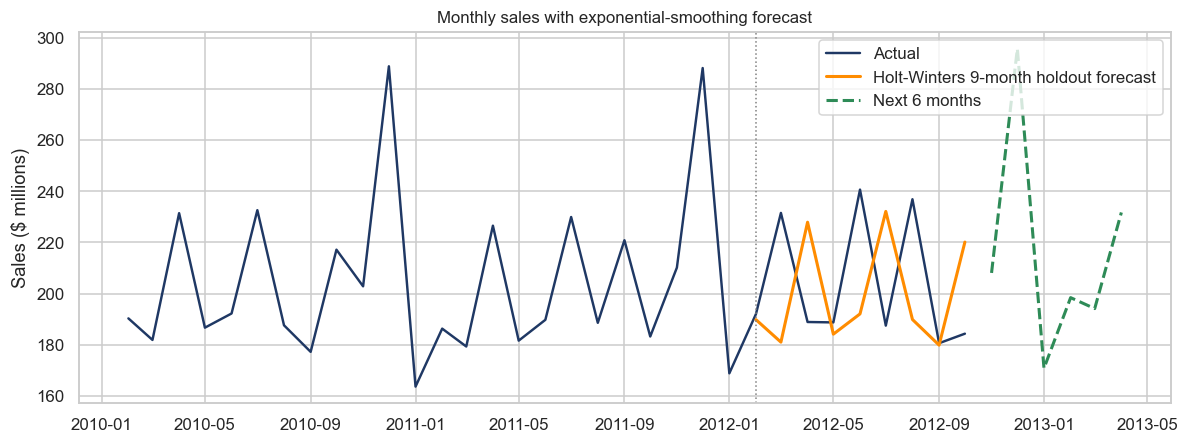


next 6 months ($ millions):
2012-11-01    208.1
2012-12-01    295.6
2013-01-01    170.9
2013-02-01    198.4
2013-03-01    194.2
2013-04-01    231.7
Freq: MS


In [10]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing

y = monthly.Sales.asfreq('MS')
HOLDOUT = 9
train_y, test_y = y[:-HOLDOUT], y[-HOLDOUT:]

fit = ExponentialSmoothing(train_y, trend='add', seasonal='add', seasonal_periods=12).fit()
fc = fit.forecast(HOLDOUT)

def mape(actual, pred):
    return float(np.mean(np.abs((actual - pred) / actual)) * 100)

naive = pd.Series(train_y.iloc[-1], index=test_y.index)
roll = pd.Series(train_y.iloc[-3:].mean(), index=test_y.index)

print(f'Holt-Winters MAPE : {mape(test_y, fc):.1f}%')
print(f'last-value MAPE   : {mape(test_y, naive):.1f}%')
print(f'3-month mean MAPE : {mape(test_y, roll):.1f}%')

full_fit = ExponentialSmoothing(y, trend='add', seasonal='add', seasonal_periods=12).fit()
future = full_fit.forecast(6)

fig, ax = plt.subplots(figsize=(11, 4.2))
ax.plot(y.index, y / 1e6, label='Actual', color='#1f3864', lw=1.6)
ax.plot(fc.index, fc / 1e6, label='Holt-Winters 9-month holdout forecast', color='darkorange', lw=2)
ax.plot(future.index, future / 1e6, label='Next 6 months', color='seagreen', ls='--', lw=2)
ax.axvline(test_y.index[0], color='grey', ls=':', lw=1)
ax.set_title('Monthly sales with exponential-smoothing forecast')
ax.set_ylabel('Sales ($ millions)')
ax.legend()
plt.tight_layout()
plt.savefig(OUT / 'fig_forecast.png', bbox_inches='tight')
plt.show()

print('\nnext 6 months ($ millions):')
print((future / 1e6).round(1).to_string())


## 9. Key findings

In [11]:
peak = index.idxmax()
trough = index.idxmin()
peak_name = pd.Timestamp(2020, peak, 1).strftime('%B')
trough_name = pd.Timestamp(2020, trough, 1).strftime('%B')
full_years = df[df.Year < 2012].groupby('Year').Weekly_Sales.sum()
growth_1011 = full_years[2011] / full_years[2010] - 1

print('KEY FINDINGS')
print(f"1. Sales grew {growth_1011:+.1%} from 2010 to 2011, and the 12-month moving average")
print(f"   ends {monthly.Rolling12.iloc[-1]/monthly.Rolling12.iloc[11]-1:+.1%} above where it started.")
print(f"2. {peak_name} is the strongest month (index {index.max():.2f}); {trough_name} the weakest ({index.min():.2f}).")
print(f"3. Holiday weeks sell {lift:+.1%} more than ordinary weeks on average;")
print(f"   Thanksgiving week is the single largest week of the year.")
print(f"4. The ten biggest departments are {share.sum()/df.Weekly_Sales.sum():.1%} of revenue;")
print(f"   like-for-like, dept {growth.iloc[0].Dept:.0f} grew {growth.iloc[0]['change_%']:+.1f}% and")
print(f"   dept {growth.iloc[-1].Dept:.0f} fell {growth.iloc[-1]['change_%']:+.1f}% (Feb-Oct 2012 vs Feb-Oct 2010).")
print(f"5. Type A stores are {df[df.Type=='A'].Store.nunique()} stores but {type_share['A']:.1%} of revenue.")
print(f"6. Holt-Winters beats the naive baselines ({mape(test_y, fc):.1f}% MAPE), so the monthly shape")
print(f"   is predictable from history alone; the next quarter is forecast around ${future.mean()/1e6:.0f}M/month.")


KEY FINDINGS
1. Sales grew +7.0% from 2010 to 2011, and the 12-month moving average
   ends +1.9% above where it started.
2. December is the strongest month (index 1.40); January the weakest (0.81).
3. Holiday weeks sell +7.8% more than ordinary weeks on average;
   Thanksgiving week is the single largest week of the year.
4. The ten biggest departments are 46.0% of revenue;
   like-for-like, dept 92 grew +11.0% and
   dept 72 fell -3.9% (Feb-Oct 2012 vs Feb-Oct 2010).
5. Type A stores are 22 stores but 64.3% of revenue.
6. Holt-Winters beats the naive baselines (14.4% MAPE), so the monthly shape
   is predictable from history alone; the next quarter is forecast around $216M/month.
